In [ ]:
# 1. SSDM 구현 소스 불러오기: 긴 문자열 대신 Drive의 ZIP 파일 사용
import io, zipfile, sys, json, os, hashlib
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF','expandable_segments:True')
from pathlib import Path
import torch
from google.colab import drive
if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
SOURCE_ZIP = Path('/content/drive/MyDrive/SSDM320_full_run/ssdm_sources_792e0632e814.zip')
_package_bytes = SOURCE_ZIP.read_bytes()
assert hashlib.sha256(_package_bytes).hexdigest() == '792e0632e814c4975a3fd702e8e56bc2a51548a5011bb68b35e4410da1bdb7bf', '구현 소스 ZIP이 변경되었습니다.'
package_root=Path('/content/ssdm_paper')
package_root.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile(io.BytesIO(_package_bytes)) as archive:
    archive.extractall(package_root)
if str(package_root) not in sys.path: sys.path.insert(0,str(package_root))
for module_name in ['ssdm_experiment','ssdm_cdl','ssdm_sampling','ssdm_backbone','ssdm_checks','check_backbone','ssdm_cache','ssdm_memory','ssdm_compact','ssdm_drive_lazy']:
    sys.modules.pop(module_name,None)
torch.set_num_threads(2)
assert torch.cuda.is_available(), 'GPU 런타임에 연결하세요.'
print('GPU:',torch.cuda.get_device_name(0),'| torch:',torch.__version__)
print('Sources installed:',package_root)
print('Source bundle SHA256:',hashlib.sha256(_package_bytes).hexdigest())
print('실험: 320x320 / 8성분 / 축소 U-Net / 검증 설정 선택 / 분리된 최종 평가')


Mounted at /content/drive
GPU: Tesla T4 | torch: 2.11.0+cu130
Sources installed: /content/ssdm_paper
Source bundle SHA256: 792e0632e814c4975a3fd702e8e56bc2a51548a5011bb68b35e4410da1bdb7bf
실험: 320x320 / 8성분 / 축소 U-Net / 검증 설정 선택 / 분리된 최종 평가


In [ ]:
# 2. 축소 모델 실험 불러오기: 기존 MRI 데이터 사용
base=Path('/content/drive/MyDrive/SSDM320_full_run')
source=(base/'ssdm_compact.py').read_bytes()
assert hashlib.sha256(source).hexdigest()=='28f35edc10b57401c2c04c4a93b3be01ac84b213c87dfc7ea9aa2596ecb6b454'
(package_root/'ssdm_compact.py').write_bytes(source)
(package_root/'ssdm_drive_lazy.py').write_bytes((base/'ssdm_drive_lazy.py').read_bytes())
for name in ['ssdm_compact','ssdm_drive_lazy']: sys.modules.pop(name,None)
from ssdm_compact import CompactRun
run=CompactRun(str(base))


Compact experiment: /content/drive/MyDrive/SSDM320_full_run/compact320_20261023 train 11029 dev4 / final8 disjoint volumes


In [ ]:
# 3. 320x320 / 8성분 축소 모델: 실제 학습 메모리 검사
preflight=run.preflight()


Frozen train-only component scale: 0.053315447148167154
MEMORY PREFLIGHT {"parameters": 23151810, "seconds_per_step": 2.069342851638794, "steps": [{"noise": 1.0016154050827026, "reconstruction": 4580.83447265625, "grad": 22.03359031677246, "updated": true}, {"noise": 0.9928908944129944, "reconstruction": 3.2058095932006836, "grad": 2.9755334854125977, "updated": true}, {"noise": 0.9823054075241089, "reconstruction": 30.97321128845215, "grad": 3.678203582763672, "updated": true}], "system_used_GiB": 2.662, "process_RSS_GiB": 2.11, "GPU_peak_GiB": 3.321}


In [ ]:
# 4. 사전 고정한 실험 계획 확인
print(json.dumps(run.protocol,indent=2,ensure_ascii=False))
print('학습률 후보: 1e-4, 3e-4 / 검증4개 / 최종평가8개')
print('최종평가 영상은 설정 선택에 사용하지 않습니다.')


{
  "schema": 1,
  "seed": 20261023,
  "architecture": {
    "image_size": 320,
    "subspaces": 8,
    "model_channels": 64,
    "num_res_blocks": 1,
    "channel_mult": [
      1,
      1,
      2,
      2,
      4,
      4
    ],
    "attention_downsample_factors": [
      20
    ],
    "num_head_channels": 32,
    "cross_attention_heads": 4,
    "dropout": 0.0,
    "use_checkpoint": true
  },
  "cdl_sha256": "495d04de7d87a340b3ffd70887c1a4723e76f5eef224263b25e1f42b34ec5d98",
  "cdl_updates": 1600,
  "cdl_completed": false,
  "train_index_hash": "67aeb89deeb8a5f2fd1116491774a06c679a8d216e43212120715a4e1ac15b6b",
  "train_volumes": 310,
  "train_slices": 11029,
  "dev": [
    {
      "file": "file1001122.h5",
      "slice": 18
    },
    {
      "file": "file1001793.h5",
      "slice": 17
    },
    {
      "file": "file1001450.h5",
      "slice": 17
    },
    {
      "file": "file1000635.h5",
      "slice": 19
    }
  ],
  "final": [
    {
      "file": "file1001818.h5",
      "sli

In [ ]:
# 5. 두 학습률을 같은 학습량으로 비교하고 검증으로 선택
selection=run.tune()
print('선택 완료:',selection['candidate'],'학습 횟수:',selection['updates'])


Frozen train-only component scale: 0.053315447148167154
TRAIN lr1e-4 0 -> 300
lr1e-4 step 1 noise 1.00162 rec 4580.73975 sec/update 2.35
lr1e-4 step 2 noise 0.99324 rec 3.16359 sec/update 2.51
lr1e-4 step 25 noise 0.71079 rec 43.90043 sec/update 2.09
lr1e-4 step 50 noise 0.42892 rec 26.29364 sec/update 2.05
lr1e-4 step 75 noise 0.24944 rec 5.22801 sec/update 2.01
lr1e-4 step 100 noise 0.0993 rec 10053.60352 sec/update 1.97
lr1e-4 step 125 noise 0.03673 rec 24.51105 sec/update 1.96
lr1e-4 step 150 noise 0.01518 rec 2445.78125 sec/update 1.92
lr1e-4 step 175 noise 0.1502 rec 2.44089 sec/update 1.91
lr1e-4 step 200 noise 0.00815 rec 61.90791 sec/update 1.9
lr1e-4 step 225 noise 0.01051 rec 5.58132 sec/update 1.92
lr1e-4 step 250 noise 0.00674 rec 30.699 sec/update 1.9
lr1e-4 step 275 noise 0.00811 rec 59.92744 sec/update 1.88
lr1e-4 step 300 noise 0.00575 rec 94.92383 sec/update 1.87
EVAL dev lr1e-4 file1001122.h5 R 8 SSDM {'PSNR': 9.420284169204635, 'SSIM': 0.022741864119314444, 'MAE': 0

In [ ]:
# 6. 최종 평가 전에 선택한 설정과 가중치 고정
selection=json.loads((run.root/'selection.json').read_text())
print('고정된 모델:',selection['candidate'],selection['updates'])
print('복원: 100-step DDIM + CG + 전역 측정 일치 + resampling')


고정된 모델: lr3e-4 900
복원: 100-step DDIM + CG + 전역 측정 일치 + resampling


In [ ]:
# 7. 설정 선택에 쓰지 않은 8개 영상 × R8/R16 최종 평가
final_results=run.final_evaluation()
print('최종 평가 완료:',final_results['complete'])


EVAL final lr3e-4 file1001818.h5 R 8 SSDM {'PSNR': 18.88519965516782, 'SSIM': 0.21194935819663888, 'MAE': 0.08819799876227875} ZF {'PSNR': 20.354885773073732, 'SSIM': 0.2797733055512698, 'MAE': 0.07577529533201727}
EVAL final lr3e-4 file1001818.h5 R 16 SSDM {'PSNR': 18.440237001363617, 'SSIM': 0.14243510627932227, 'MAE': 0.09279834154437211} ZF {'PSNR': 19.767724942479227, 'SSIM': 0.18941415415530016, 'MAE': 0.0814822009573794}
EVAL final lr3e-4 file1001968.h5 R 8 SSDM {'PSNR': 21.233150190256215, 'SSIM': 0.2596187696418489, 'MAE': 0.06489392619333031} ZF {'PSNR': 23.77348156604623, 'SSIM': 0.39536620742143325, 'MAE': 0.047838688660106356}
EVAL final lr3e-4 file1001968.h5 R 16 SSDM {'PSNR': 21.17106643527787, 'SSIM': 0.24276019393102624, 'MAE': 0.06478418981878263} ZF {'PSNR': 23.54645183468927, 'SSIM': 0.34895561010139026, 'MAE': 0.049185395359601924}
EVAL final lr3e-4 file1000748.h5 R 8 SSDM {'PSNR': 20.032755421611625, 'SSIM': 0.22429805002082673, 'MAE': 0.07684921918177451} ZF {'PS

R 8 mean paired PSNR change -2.0061 dB; wins 0 / 8
R 16 mean paired PSNR change -2.1254 dB; wins 0 / 8
 R      method  n      PSNR     SSIM      MAE
 8 zero_filled  8 22.933171 0.392965 0.054347
 8        ssdm  8 20.927056 0.256917 0.069155
16 zero_filled  8 22.475989 0.333720 0.057216
16        ssdm  8 20.350619 0.208862 0.073143
Reduced-width SSDM; partial CDL and training data. Full paper reproduction: False.


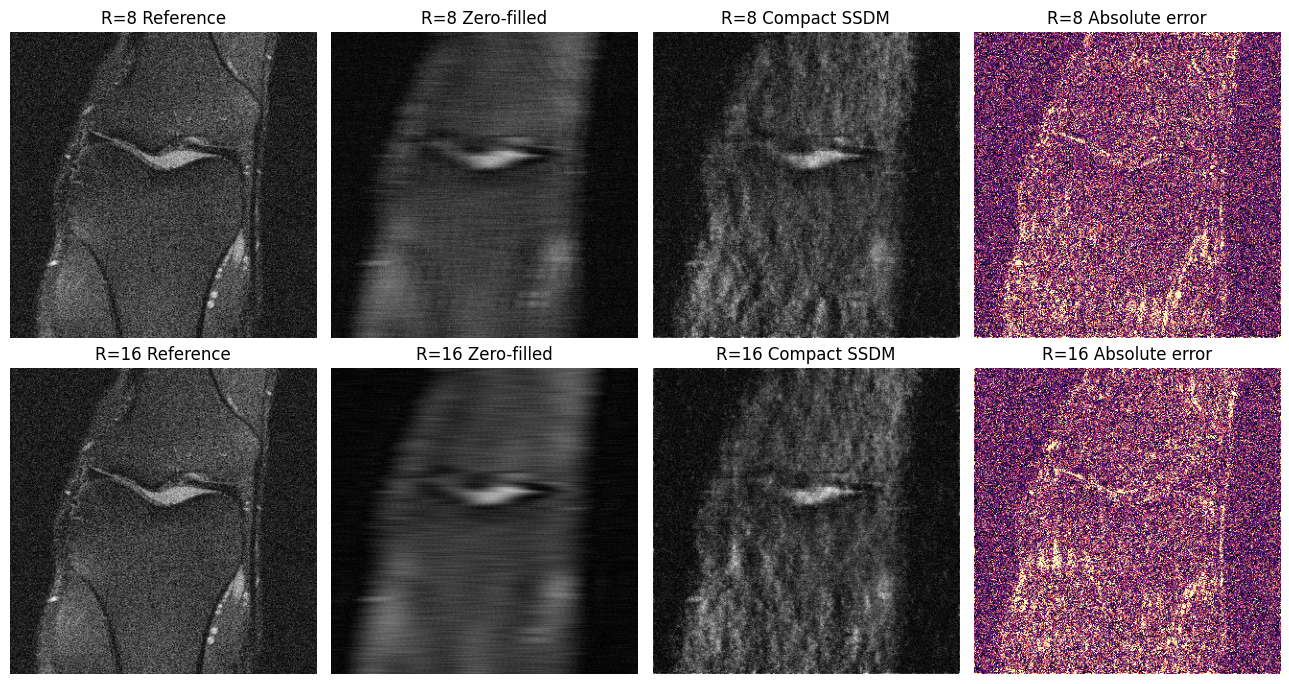

비교 영상: /content/drive/MyDrive/SSDM320_full_run/compact320_20261023/comparison.png


In [ ]:
# 8. zero-filled와 축소 SSDM의 실제 성능 및 영상 비교
summary=run.report()
import matplotlib.pyplot as plt
import numpy as np
r=json.loads((run.root/'final_results.json').read_text())
folder=run.root/'evaluations'/f"{r['candidate']}_{r['checkpoint_sha256'][:12]}_final"
fig,axes=plt.subplots(2,4,figsize=(13,7))
for row,R in enumerate((8,16)):
    with np.load(folder/f'00_R{R}.npz') as a:
        pictures=[a['reference'],a['zero_filled'],a['ssdm'],np.abs(a['ssdm']-a['reference'])]
        for col,(title,picture) in enumerate(zip(['Reference','Zero-filled','Compact SSDM','Absolute error'],pictures)):
            axes[row,col].imshow(picture,cmap='gray' if col<3 else 'magma',vmin=0,vmax=1 if col<3 else .2)
            axes[row,col].set_title(f'R={R} {title}'); axes[row,col].axis('off')
fig.tight_layout(); fig.savefig(run.root/'comparison.png',dpi=150)
plt.show()
print('비교 영상:',run.root/'comparison.png')


In [ ]:
# 9. 개선 전 진단: 기존 가중치와 결과는 변경하지 않음
import numpy as np
import ssdm_experiment as ex
from ssdm_cdl import complex_to_ri, ri_to_complex, fft2c, ifft2c
from ssdm_sampling import sampling_smoke_tests
numerical = sampling_smoke_tests('cuda')
audit=[]
with torch.no_grad():
    for case in run.protocol['dev']:
        x=run._read_val(case)
        full=run.cdl(complex_to_ri(x))
        row=dict(file=case['file'],cdl_rel_error=float((ri_to_complex(full.reconstruction)-x).norm()/x.norm()),**ex.metric_values(x.abs()[0].cpu().numpy(),ri_to_complex(full.reconstruction).abs()[0].cpu().numpy()))
        audit.append(row); print('CDL DIAGNOSTIC',row,flush=True)
newroot=base/'improve320_v2'
newroot.mkdir(exist_ok=True)
ex.json_write(newroot/'diagnostic.json',dict(numerical=numerical,cdl=audit))
print('DIAGNOSTIC COMPLETE',flush=True)


Sampler numerical checks passed. These checks do not establish image quality.
{'cg_analytic_relative_error': 1.7912407201947644e-07, 'cg_normal_relative_residual': 9.02853187767505e-08, 'global_dc_relative_error': 4.0901551301431027e-07, 'max_subject_dc_relative_error': 4.115267131510336e-07, 'unobserved_frequency_relative_change': 1.2271617322312522e-07, 'resample_mean_error': -0.0034077689051628113, 'resample_variance_ratio': 0.9993693828582764, 'zero_epsilon_100step_dc': 1.0869470088437083e-06}
CDL DIAGNOSTIC {'file': 'file1001122.h5', 'cdl_rel_error': 0.04069390892982483, 'PSNR': 43.27922232040524, 'SSIM': 0.985257855899916, 'MAE': 0.004634541679861996}
CDL DIAGNOSTIC {'file': 'file1001793.h5', 'cdl_rel_error': 0.02503519505262375, 'PSNR': 45.003588544596305, 'SSIM': 0.994282652893479, 'MAE': 0.003511732095793718}
CDL DIAGNOSTIC {'file': 'file1001450.h5', 'cdl_rel_error': 0.03480681777000427, 'PSNR': 44.70171783067664, 'SSIM': 0.9956985244193385, 'MAE': 0.004251683356430078}
CDL DI

In [ ]:
# 끊어진 Drive 마운트 복구
drive.mount('/content/drive', force_remount=True)
print('Drive ready:', SOURCE_ZIP.is_file())

Mounted at /content/drive
Drive ready: True


In [ ]:
# 11. 개선 모듈 불러오기
v2_source=(base/'ssdm_improve_v2.py').read_bytes()
assert hashlib.sha256(v2_source).hexdigest()=='4125dfcf81a55f85924ec44b6bfd1649f4b257f6c10efad3a702376e2d60a3c6'
(package_root/'ssdm_improve_v2.py').write_bytes(v2_source)
print('개선 모듈 준비 완료')


개선 모듈 준비 완료


In [ ]:
# 12. 저장된 모델·평가부터 재개 (Drive 연결 오류는 최대 3회 복구)
import importlib, gc, time
import numpy as np
import ssdm_improve_v2
importlib.reload(ssdm_improve_v2)
for reconnect_attempt in range(4):
    try:
        v2=ssdm_improve_v2.ImprovementRun(str(base))
        status_path=v2.root/'lr3e-4_status.json'
        print('저장된 진행:',status_path.read_text() if status_path.exists() else '아직 없음',flush=True)
        v2_results=v2.execute()
        break
    except OSError as connection_error:
        if connection_error.errno != 107 or reconnect_attempt == 3:
            raise
        print('Drive 연결 복구 후 저장 지점부터 재개:',reconnect_attempt+1,flush=True)
        gc.collect(); torch.cuda.empty_cache()
        drive.mount('/content/drive',force_remount=True)


Compact experiment: /content/drive/MyDrive/SSDM320_full_run/compact320_20261023 train 11029 dev4 / final8 disjoint volumes
저장된 진행: {
  "updates": 6000,
  "attempts": 6000,
  "last": {
    "noise": 0.0030263543594628572,
    "reconstruction": 4.441753387451172,
    "grad": 0.776818573474884,
    "updated": true
  },
  "system_used_GiB": 2.853,
  "process_RSS_GiB": 2.049,
  "GPU_peak_GiB": 3.343
}
DIFFUSION READY CDL extra 1000 scale 0.05468132945688502
LOCAL CACHE file1001122.h5 25.4 MiB
V2 EVAL dev sampler1 3000 file1001122.h5 8 deltaPSNR -1.535
V2 EVAL dev sampler1 3000 file1001122.h5 16 deltaPSNR -1.418
LOCAL CACHE file1001793.h5 24.2 MiB
V2 EVAL dev sampler1 3000 file1001793.h5 8 deltaPSNR -1.46
V2 EVAL dev sampler1 3000 file1001793.h5 16 deltaPSNR -0.994
LOCAL CACHE file1001450.h5 24.2 MiB
V2 EVAL dev sampler1 3000 file1001450.h5 8 deltaPSNR -1.028
V2 EVAL dev sampler1 3000 file1001450.h5 16 deltaPSNR -0.894
V2 EVAL dev sampler1 3000 file1000635.h5 8 deltaPSNR -1.181
V2 EVAL dev sa

In [9]:
# 13. 평가 완료·저장 파일·메모리 확인
import torch, psutil, gc, json
gc.collect(); torch.cuda.empty_cache()
result_root=base/'improve320_v2'
result=json.loads((result_root/'final_results.json').read_text())
print('최종 평가 완료:',result['complete'],'| 평가 건수:',len(result['records']))
for name in ['selection.json','final_results.json','summary.json','comparison.png']:
    p=result_root/name
    print(name, '저장됨:',p.exists(), '| bytes:',p.stat().st_size if p.exists() else 0)
print('RAM used GiB:',round(psutil.virtual_memory().used/2**30,2))
print('Python RSS GiB:',round(psutil.Process().memory_info().rss/2**30,2))


최종 평가 완료: True | 평가 건수: 32
selection.json 저장됨: True | bytes: 2059
final_results.json 저장됨: True | bytes: 12715
summary.json 저장됨: True | bytes: 5589
comparison.png 저장됨: True | bytes: 2604011
RAM used GiB: 2.73
Python RSS GiB: 1.75


 R      method  n      PSNR     SSIM      MAE
 8 zero_filled 16 22.969293 0.440291 0.052154
 8        ssdm 16 22.892082 0.404317 0.053688
16 zero_filled 16 22.562988 0.395169 0.054191
16        ssdm 16 22.296768 0.345873 0.056800


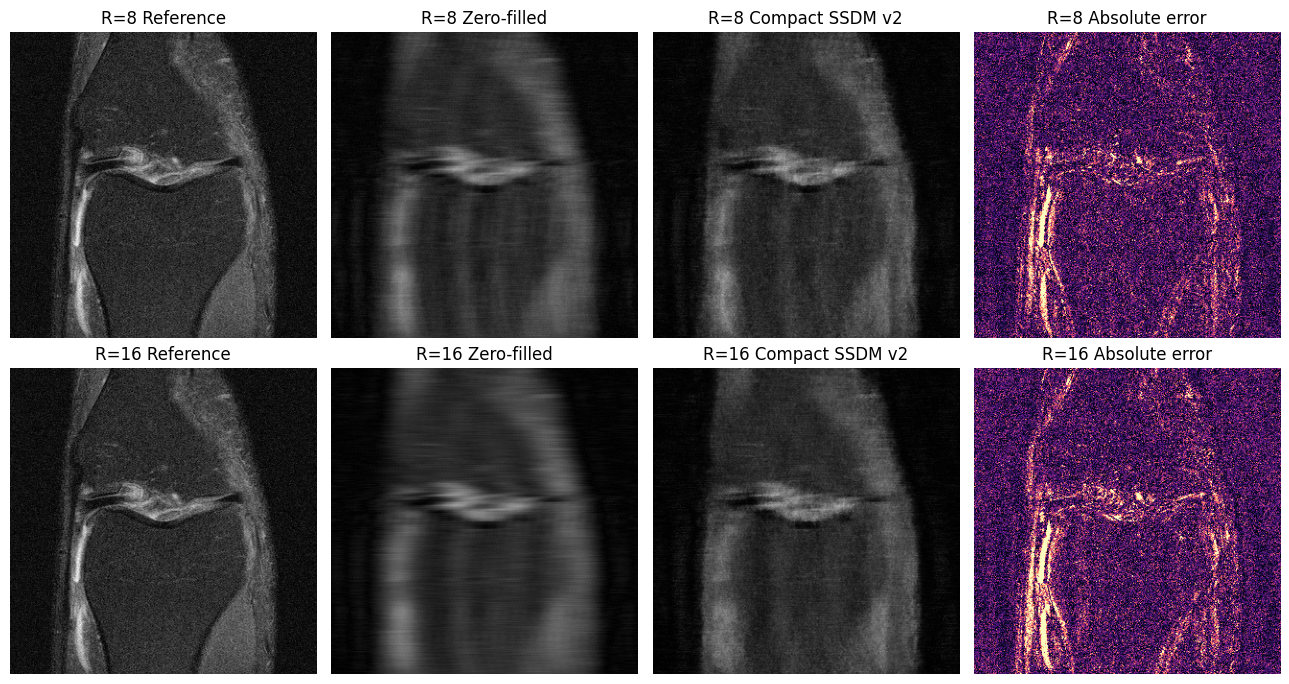

Reduced model; partial training. Final evaluation uses 16 new volumes.


In [ ]:
# 14. 새 평가 영상 비교: 성능 선택이 끝난 후 실행
import matplotlib.pyplot as plt
import pandas as pd
root=base/'improve320_v2'
s=json.loads((root/'summary.json').read_text())
print(pd.DataFrame(s['rows']).to_string(index=False))
choice=s['selection']
folder=root/'evaluations'/f"{choice['checkpoint_sha256'][:12]}_{choice['tag']}_final"
fig,axes=plt.subplots(2,4,figsize=(13,7))
for i,R in enumerate((8,16)):
    with np.load(folder/f'00_R{R}.npz') as a:
        pics=[a['reference'],a['zero_filled'],a['ssdm'],abs(a['ssdm']-a['reference'])]
        for j,(label,pic) in enumerate(zip(['Reference','Zero-filled','Compact SSDM v2','Absolute error'],pics)):
            axes[i,j].imshow(pic,cmap='gray' if j<3 else 'magma',vmin=0,vmax=1 if j<3 else .2)
            axes[i,j].set_title(f'R={R} {label}');axes[i,j].axis('off')
fig.tight_layout();fig.savefig(root/'comparison.png',dpi=150);plt.show()
print('Reduced model; partial training. Final evaluation uses 16 new volumes.')
